## 4. Evaluation

### 4.1 Overview

In [3]:
import pandas as pd
import numpy as np
np.set_printoptions(legacy="1.25")

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [4]:
url = "https://raw.githubusercontent.com/alexeygrigorev/mlbookcamp-code/master/chapter-03-churn-prediction/WA_Fn-UseC_-Telco-Customer-Churn.csv"
df = pd.read_csv(url) 


In [5]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

categorical_columns = [c for c in df.columns if pd.api.types.is_string_dtype(df[c])]
for c in categorical_columns:
    df[c] = df[c].str.lower().str.replace(' ', '_')

df.totalcharges = pd.to_numeric(df.totalcharges, errors='coerce')
df.totalcharges = df.totalcharges.fillna(0)

df.churn = (df.churn == 'yes').astype(int)

In [6]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train.churn.values
y_val = df_val.churn.values
y_test = df_test.churn.values

del df_train['churn']
del df_val['churn']
del df_test['churn']

In [7]:
numerical = ['tenure', 'monthlycharges', 'totalcharges']

categorical = [
    'gender', 'seniorcitizen', 'partner', 'dependents',
    'phoneservice', 'multiplelines', 'internetservice',
    'onlinesecurity', 'onlinebackup', 'deviceprotection', 'techsupport',
    'streamingtv', 'streamingmovies', 'contract', 'paperlessbilling',
    'paymentmethod',
]

In [9]:
dv = DictVectorizer(sparse=False)

train_dicts = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dicts)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

val_dicts = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dicts)

y_pred = model.predict_proba(X_val)[:, 1]
churn_decision = (y_pred >= 0.5)


c:\Users\marco\Documents\ml-zoomcamp\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


### 4.2 Accuracy and Dummy Model

In [10]:
len(y_val)

1409

In [11]:
(y_val == churn_decision).mean()

0.8062455642299503

In [13]:
1132 / 1409

0.8034066713981547

In [17]:
from sklearn.metrics import accuracy_score

In [18]:
accuracy_score(y_val, y_pred >= 0.5)

0.8062455642299503

In [19]:
thresholds = np.linspace(0, 1, 21) 

scores = [] 

for t in thresholds: 
    score = accuracy_score(y_val, y_pred >= t) 
    print('%.2f %.3f' % (t, score)) 
    scores.append(score)


0.00 0.274
0.05 0.512
0.10 0.607
0.15 0.661
0.20 0.703
0.25 0.735
0.30 0.759
0.35 0.768
0.40 0.781
0.45 0.791
0.50 0.806
0.55 0.803
0.60 0.797
0.65 0.787
0.70 0.767
0.75 0.743
0.80 0.730
0.85 0.726
0.90 0.726
0.95 0.726
1.00 0.726


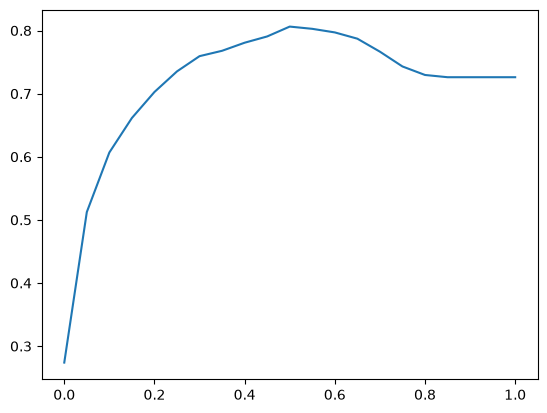

In [15]:
plt.plot(thresholds, scores)

In [20]:
from collections import Counter 

In [21]:
Counter(y_pred >= 1.0)

Counter({False: 1409})

In [22]:
Counter(y_val)

Counter({0: 1023, 1: 386})